## 1. Setup

In [1]:
!pip install -q -U transformers datasets accelerate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.3/12.3 MB 55.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 559.1/559.1 kB 21.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 394.3/394.3 kB 20.1 MB/s eta 0:00:00


In [2]:
import os, re, random, time, warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import transformers

from datasets import load_dataset, Dataset
from transformers import (AutoConfig, AutoTokenizer, AutoModel, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, DataCollatorWithPadding, set_seed)
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, f1_score, classification_report, confusion_matrix)
from sklearn.manifold import TSNE
from sklearn.utils.class_weight import compute_class_weight
from IPython.display import HTML, display

warnings.filterwarnings("ignore")
os.environ["WANDB_DISABLED"] = "true"

SEED = 42
set_seed(SEED); random.seed(SEED); np.random.seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("transformers:", transformers.__version__, "| torch:", torch.__version__)
print("Device:", device, "|", torch.cuda.get_device_name(0) if torch.cuda.is_available()
      else "CPU only (fine-tuning will be very slow - switch to a T4 GPU runtime!)")

sns.set_theme(style="whitegrid", font_scale=1.0)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titleweight"] = "bold"

COLORS = {"sadness": "#3b82c4", "joy": "#f5b700", "love": "#e75480",
          "anger": "#d62828", "fear": "#7b4fbf", "surprise": "#f77f00"}

transformers: 5.17.0 | torch: 2.11.0+cu128
Device: cuda | Tesla T4


In [3]:
raw = load_dataset("dair-ai/emotion")          # official train / validation / test splits
print(raw)

LABELS = raw["train"].features["label"].names   # ['sadness','joy','love','anger','fear','surprise']
NUM_LABELS = len(LABELS)
id2label = dict(enumerate(LABELS)); label2id = {v: k for k, v in id2label.items()}

train_df = raw["train"].to_pandas()
val_df   = raw["validation"].to_pandas()
test_df  = raw["test"].to_pandas()
print(f"Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)} | Classes: {LABELS}")

train_df.sample(8, random_state=3).assign(emotion=lambda d: d.label.map(id2label))[["text", "emotion"]]

README.md:   0%|          | 0.00/9.05k [00:00<?, ?B/s]

split/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.03MB            

split/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  127kB            

split/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

Generating train split:   0%|          | 0/16000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 16000
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
})
Train: 16000 | Val: 2000 | Test: 2000 | Classes: ['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']


,text,emotion
4766,i am back at home feeling irritable about that...,anger
3788,im feeling as if im not caring and i dont want...,love
5806,i need to be intentional to do more things lik...,joy
3251,i go to sleep as soon as my head hits the pill...,sadness
456,i feel so honoured to have hosted this series ...,joy
10418,i have to relate it to how a subject percieves...,sadness
143,i just feel really violent right now,anger
4749,i feel oddly nostalgic for those early days wh...,love


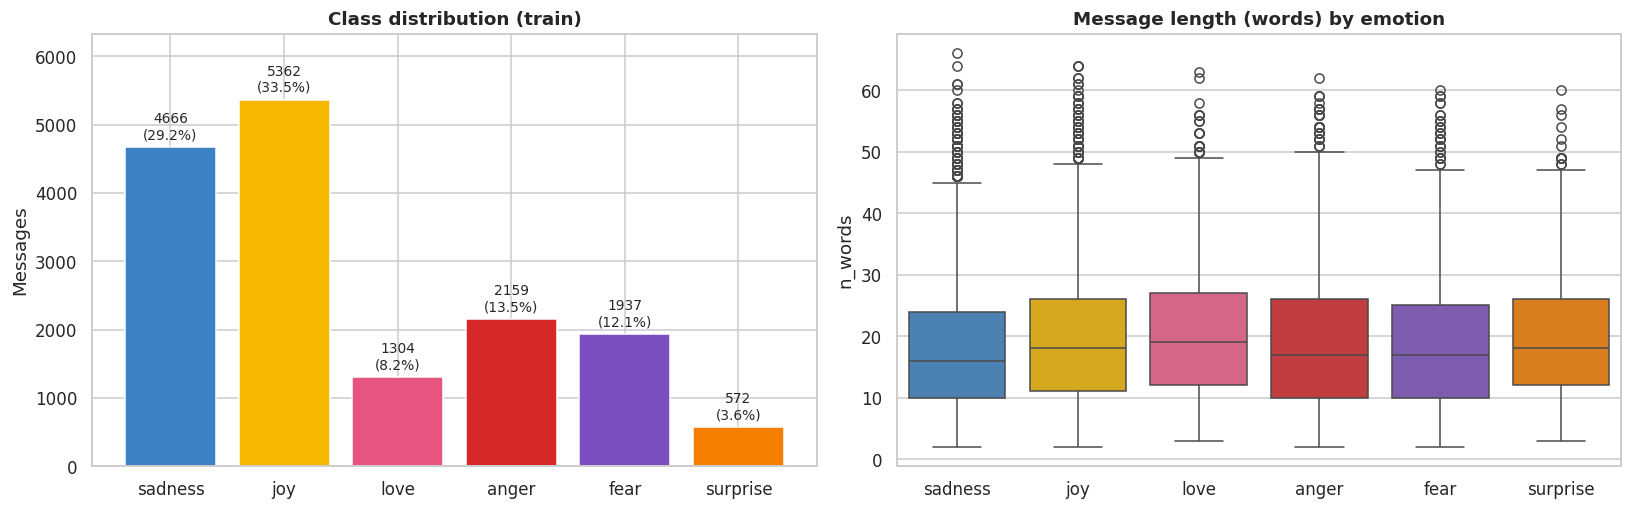

In [4]:
train_df["n_words"] = train_df.text.str.split().str.len()
train_df["emotion"] = train_df.label.map(id2label)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
counts = train_df.label.value_counts().sort_index()
axes[0].bar(LABELS, counts.values, color=[COLORS[l] for l in LABELS])
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 120, f"{v}\n({v/counts.sum():.1%})", ha="center", fontsize=9)
axes[0].set_title("Class distribution (train)"); axes[0].set_ylabel("Messages"); axes[0].set_ylim(0, counts.max() * 1.18)

sns.boxplot(data=train_df, x="emotion", y="n_words", order=LABELS, hue="emotion",
            palette=COLORS, legend=False, ax=axes[1])
axes[1].set_title("Message length (words) by emotion"); axes[1].set_xlabel("")
plt.tight_layout(); plt.show()

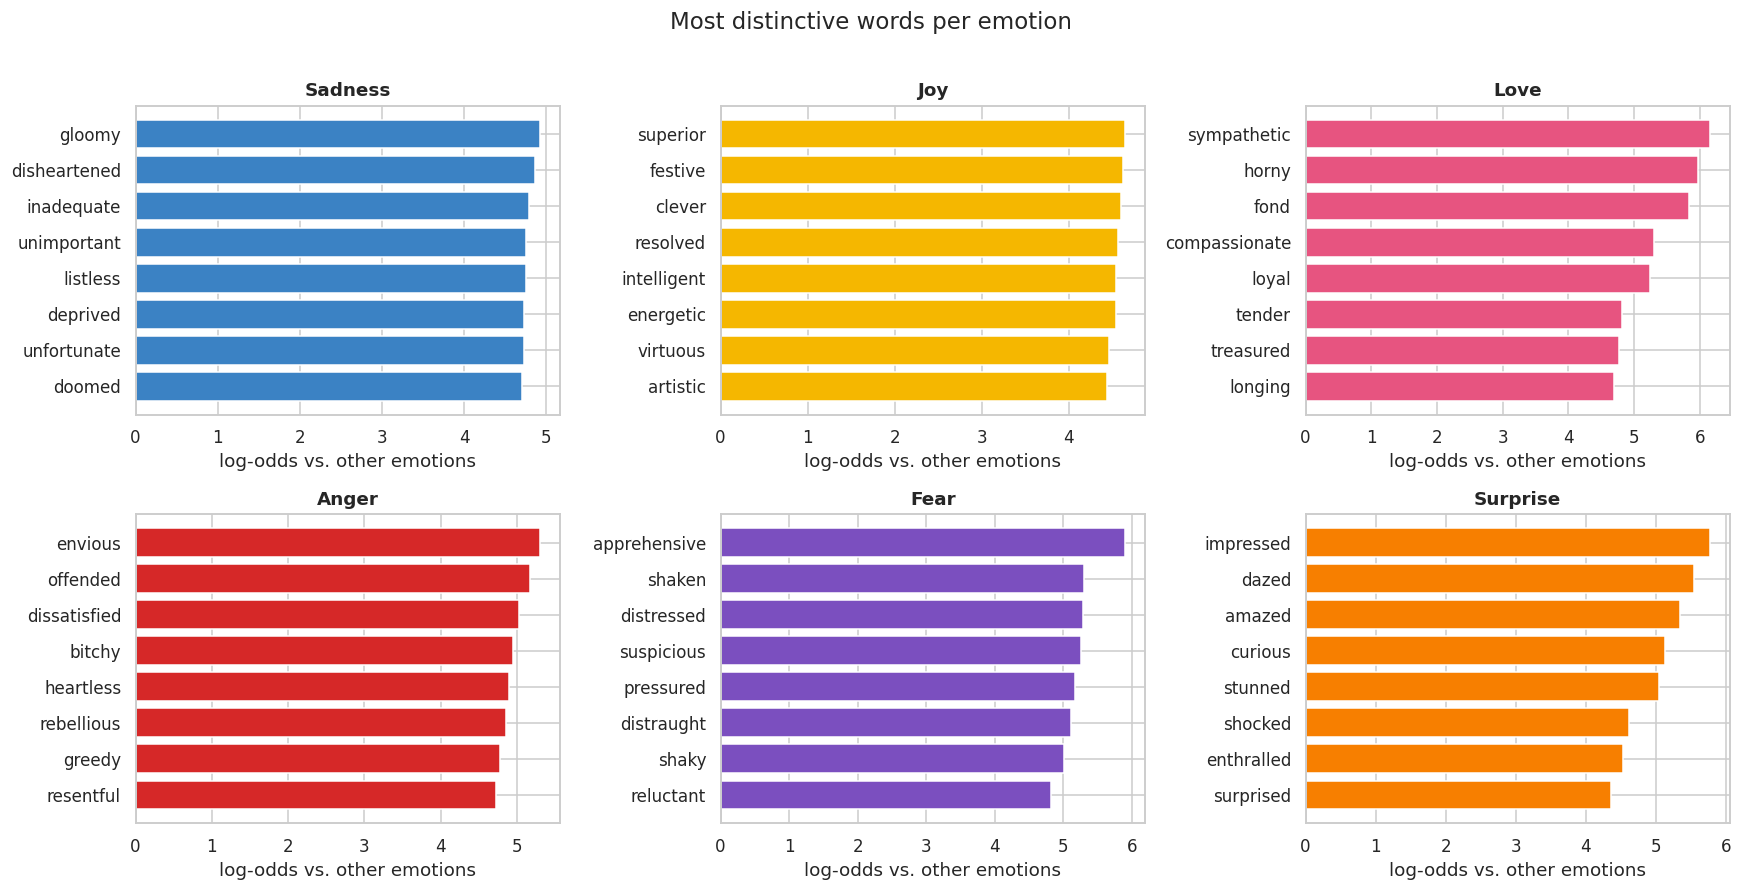

In [5]:
# Most DISTINCTIVE words per emotion via smoothed log-odds (a word frequent in every class scores ~0)
cv = CountVectorizer(stop_words="english", min_df=5)
Xc = cv.fit_transform(train_df.text)
vocab = np.array(cv.get_feature_names_out())
y_tr = train_df.label.values

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for k, ax in enumerate(axes.flat):
    in_c  = np.asarray(Xc[y_tr == k].sum(0)).ravel() + 1
    out_c = np.asarray(Xc[y_tr != k].sum(0)).ravel() + 1
    score = np.log(in_c / in_c.sum()) - np.log(out_c / out_c.sum())
    top = score.argsort()[-8:]
    ax.barh(vocab[top], score[top], color=COLORS[LABELS[k]])
    ax.set_title(LABELS[k].capitalize()); ax.set_xlabel("log-odds vs. other emotions")
plt.suptitle("Most distinctive words per emotion", fontsize=15, y=1.01)
plt.tight_layout(); plt.show()

In [6]:
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
Xtr = tfidf.fit_transform(train_df.text); Xte = tfidf.transform(test_df.text)
baseline = LogisticRegression(max_iter=3000, class_weight="balanced").fit(Xtr, train_df.label)

y_true = test_df.label.values
preds = {"TF-IDF + LogReg": baseline.predict(Xte)}
print(f"Baseline -> Accuracy: {accuracy_score(y_true, preds['TF-IDF + LogReg']):.4f} | "
      f"Macro-F1: {f1_score(y_true, preds['TF-IDF + LogReg'], average='macro'):.4f}")

Baseline -> Accuracy: 0.8690 | Macro-F1: 0.8345


config.json:   0%|          | 0.00/1.19k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/20.8k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.13M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/694 [00:00<?, ?B/s]

Text  : i feel so overwhelmed and anxious about tomorrow's exam
Tokens: ['i', 'Ġfeel', 'Ġso', 'Ġoverwhelmed', 'Ġand', 'Ġanxious', 'Ġabout', 'Ġtomorrow', "'s", 'Ġexam']
IDs   : [50281, 74, 1928, 594, 29991, 285, 20138, 670, 10873, 434, 1174, 50282]


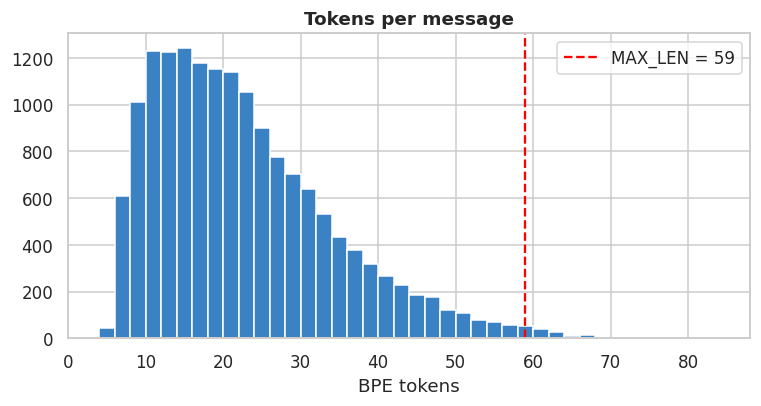

99th-percentile length -> MAX_LEN = 59 (vs. 8192 supported) => much faster training


In [7]:
MODEL_NAME = "answerdotai/ModernBERT-base"    # try "google/electra-base-discriminator" or "distilroberta-base" too
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

example = "i feel so overwhelmed and anxious about tomorrow's exam"
print("Text  :", example)
print("Tokens:", tokenizer.tokenize(example))
print("IDs   :", tokenizer(example)["input_ids"])

tok_lens = [len(x) for x in tokenizer(train_df.text.tolist())["input_ids"]]
MAX_LEN = int(np.percentile(tok_lens, 99)) + 2
plt.figure(figsize=(8, 3.6))
plt.hist(tok_lens, bins=40, color="#3b82c4", edgecolor="white")
plt.axvline(MAX_LEN, color="red", ls="--", label=f"MAX_LEN = {MAX_LEN}")
plt.title("Tokens per message"); plt.xlabel("BPE tokens"); plt.legend(); plt.show()
print(f"99th-percentile length -> MAX_LEN = {MAX_LEN} (vs. 8192 supported) => much faster training")

In [8]:
def to_hf(df):
    ds = Dataset.from_pandas(df[["text", "label"]].reset_index(drop=True))
    return ds.map(lambda b: tokenizer(b["text"], truncation=True, max_length=MAX_LEN),
                  batched=True, remove_columns=["text"])

train_ds, val_ds, test_ds = to_hf(train_df), to_hf(val_df), to_hf(test_df)
collator = DataCollatorWithPadding(tokenizer)      # pads each batch only to its own longest sequence
train_ds

Map:   0%|          | 0/16000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Dataset({
    features: ['label', 'input_ids', 'attention_mask'],
    num_rows: 16000
})

In [9]:
def get_config():
    cfg = AutoConfig.from_pretrained(MODEL_NAME)
    if hasattr(cfg, "reference_compile"):          # ModernBERT: avoid torch.compile issues on Colab
        cfg.reference_compile = False
    cfg.num_labels = NUM_LABELS; cfg.id2label = id2label; cfg.label2id = label2id
    return cfg

@torch.no_grad()
def cls_embeddings(model, texts, bs=128):
    model.eval(); out = []
    for i in range(0, len(texts), bs):
        enc = tokenizer(texts[i:i+bs], padding=True, truncation=True,
                        max_length=MAX_LEN, return_tensors="pt").to(device)
        hs = model(**enc, output_hidden_states=True).hidden_states[-1]
        out.append(hs[:, 0, :].float().cpu().numpy())
    return np.vstack(out)

t0 = time.time()
frozen = AutoModel.from_pretrained(MODEL_NAME, config=get_config()).to(device)
probe_idx = train_df.sample(4000, random_state=SEED).index
emb_probe_train  = cls_embeddings(frozen, train_df.loc[probe_idx, "text"].tolist())
emb_test_before  = cls_embeddings(frozen, test_df.text.tolist())
del frozen; torch.cuda.empty_cache()

probe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, class_weight="balanced"))
probe.fit(emb_probe_train, train_df.loc[probe_idx, "label"])
preds["Frozen ModernBERT + LogReg (probe)"] = probe.predict(emb_test_before)
print(f"Linear probe -> Accuracy: {accuracy_score(y_true, preds['Frozen ModernBERT + LogReg (probe)']):.4f} | "
      f"Macro-F1: {f1_score(y_true, preds['Frozen ModernBERT + LogReg (probe)'], average='macro'):.4f} "
      f"({time.time()-t0:.0f}s)")

viz_idx = np.random.RandomState(SEED).choice(len(test_df), 1500, replace=False)
tsne_before = TSNE(n_components=2, perplexity=35, init="pca", random_state=SEED).fit_transform(emb_test_before[viz_idx])

model.safetensors: reconstructing file:   0%|          |  0.00B /  599MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/134 [00:00<?, ?it/s]

[transformers] ModernBertModel LOAD REPORT from: answerdotai/ModernBERT-base
Key               | Status     |  | 
------------------+------------+--+-
head.norm.weight  | UNEXPECTED |  | 
head.dense.weight | UNEXPECTED |  | 
decoder.bias      | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Linear probe -> Accuracy: 0.4300 | Macro-F1: 0.3609 (67s)


In [10]:
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, config=get_config()).to(device)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable parameters: {n_params/1e6:.1f} M")

weights = compute_class_weight("balanced", classes=np.arange(NUM_LABELS), y=train_df.label)
class_w = torch.tensor(weights, dtype=torch.float).to(device)
print("Class weights:", {LABELS[i]: round(float(w), 2) for i, w in enumerate(weights)})

class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        loss = nn.CrossEntropyLoss(weight=class_w)(outputs.logits, labels)
        return (loss, outputs) if return_outputs else loss

def compute_metrics(p):
    pr = p.predictions.argmax(-1)
    return {"accuracy": accuracy_score(p.label_ids, pr),
            "macro_f1": f1_score(p.label_ids, pr, average="macro")}

Loading weights:   0%|          | 0/136 [00:00<?, ?it/s]

[transformers] ModernBertForSequenceClassification LOAD REPORT from: answerdotai/ModernBERT-base
Key               | Status     | 
------------------+------------+-
decoder.bias      | UNEXPECTED | 
classifier.bias   | MISSING    | 
classifier.weight | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Trainable parameters: 149.6 M
Class weights: {'sadness': 0.57, 'joy': 0.5, 'love': 2.04, 'anger': 1.24, 'fear': 1.38, 'surprise': 4.66}


In [11]:
EPOCHS, BATCH, LR = 3, 32, 5e-5
total_steps  = int(np.ceil(len(train_ds) / BATCH)) * EPOCHS
warmup_steps = int(0.1 * total_steps)

use_cuda = torch.cuda.is_available()
bf16_ok  = use_cuda and torch.cuda.get_device_capability()[0] >= 8     # T4 (7.5) -> fp16, A100/L4 -> bf16

args = TrainingArguments(
    output_dir="modernbert_emotion",
    num_train_epochs=EPOCHS,
    learning_rate=LR,
    per_device_train_batch_size=BATCH,
    per_device_eval_batch_size=128,
    weight_decay=0.01,
    warmup_steps=warmup_steps,
    lr_scheduler_type="linear",
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_steps=25,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    save_total_limit=1,
    fp16=use_cuda and not bf16_ok,
    bf16=bf16_ok,
    report_to="none",
    seed=SEED,
)

trainer = WeightedTrainer(model=model, args=args, train_dataset=train_ds, eval_dataset=val_ds,
                          data_collator=collator, compute_metrics=compute_metrics)
train_result = trainer.train()
print(f"\nTraining time: {train_result.metrics['train_runtime']:.0f}s")

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,0.190116,0.200787,0.923000,0.900731
2,0.102953,0.131350,0.938500,0.915409
3,0.063541,0.172846,0.941000,0.920349


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Training time: 315s


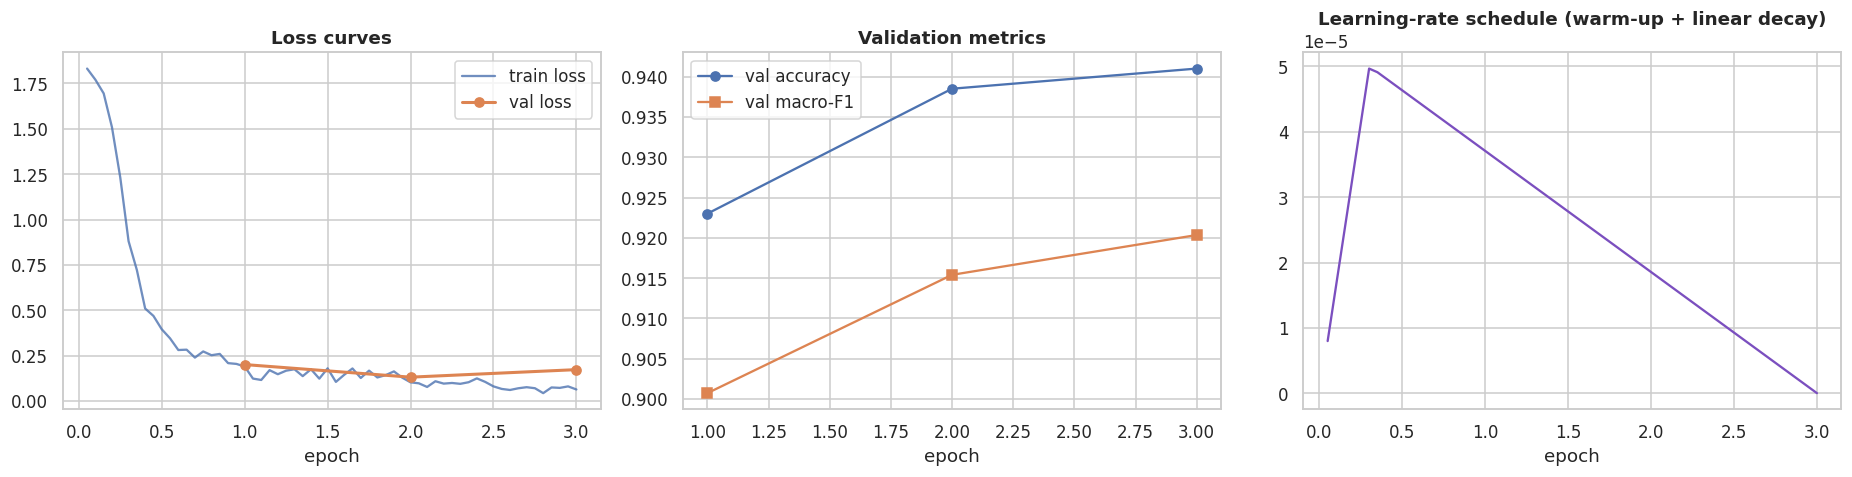

In [12]:
hist = pd.DataFrame(trainer.state.log_history)
tr = hist.dropna(subset=["loss"]); ev = hist.dropna(subset=["eval_loss"])

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].plot(tr.epoch, tr.loss, label="train loss", alpha=.8)
axes[0].plot(ev.epoch, ev.eval_loss, "o-", label="val loss", lw=2)
axes[0].set_title("Loss curves"); axes[0].set_xlabel("epoch"); axes[0].legend()

axes[1].plot(ev.epoch, ev.eval_accuracy, "o-", label="val accuracy")
axes[1].plot(ev.epoch, ev.eval_macro_f1, "s-", label="val macro-F1")
axes[1].set_title("Validation metrics"); axes[1].set_xlabel("epoch"); axes[1].legend()

axes[2].plot(tr.epoch, tr.learning_rate, color="#7b4fbf")
axes[2].set_title("Learning-rate schedule (warm-up + linear decay)"); axes[2].set_xlabel("epoch")
plt.tight_layout(); plt.show()

In [13]:
pred_out = trainer.predict(test_ds)
probs = torch.softmax(torch.tensor(pred_out.predictions), -1).numpy()
preds["Fine-tuned ModernBERT"] = probs.argmax(1)
bert_pred = preds["Fine-tuned ModernBERT"]

print(classification_report(y_true, bert_pred, target_names=LABELS, digits=4))

rows = []
for name, p in preds.items():
    rows.append({"Model": name,
                 "Accuracy": accuracy_score(y_true, p),
                 "Macro-F1": f1_score(y_true, p, average="macro"),
                 "Weighted-F1": f1_score(y_true, p, average="weighted")})
res_df = pd.DataFrame(rows).set_index("Model")
display(res_df.style.format("{:.4f}").highlight_max(color="#c8f7c5").set_caption("Test-set comparison"))

              precision    recall  f1-score   support

     sadness     0.9705    0.9621    0.9663       581
         joy     0.9745    0.9338    0.9537       695
        love     0.7872    0.9308    0.8530       159
       anger     0.9373    0.9236    0.9304       275
        fear     0.8800    0.8839    0.8820       224
    surprise     0.7297    0.8182    0.7714        66

    accuracy                         0.9310      2000
   macro avg     0.8799    0.9088    0.8928      2000
weighted avg     0.9347    0.9310    0.9321      2000



,Accuracy,Macro-F1,Weighted-F1
Model,,,
TF-IDF + LogReg,0.8690,0.8345,0.8713
Frozen ModernBERT + LogReg (probe),0.4300,0.3609,0.4455
Fine-tuned ModernBERT,0.9310,0.8928,0.9321


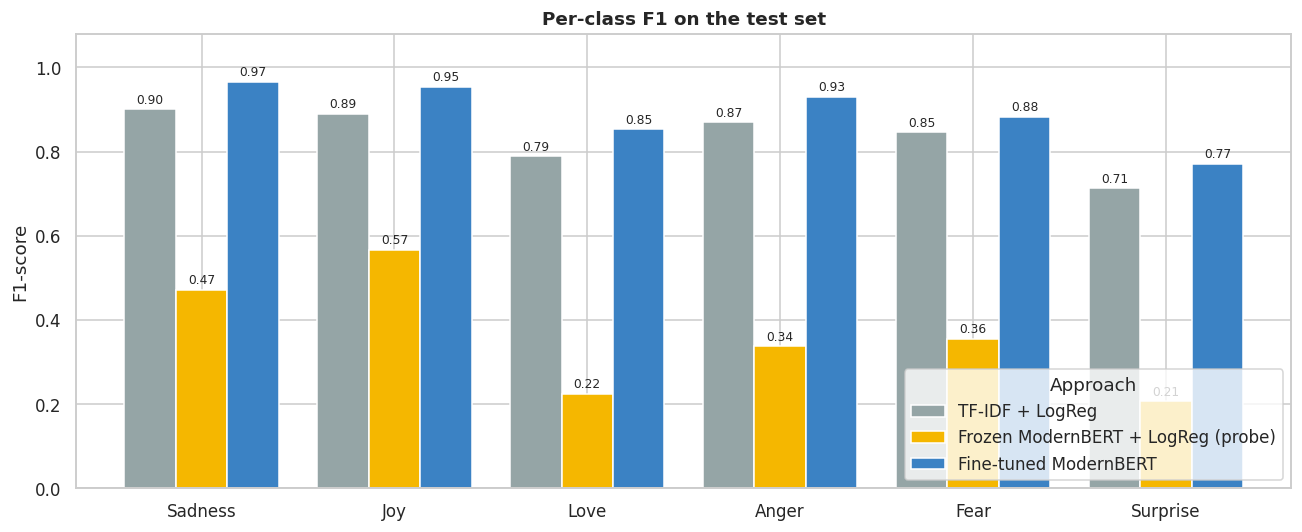

In [14]:
# Per-class F1 for all three approaches
f1_table = pd.DataFrame({name: f1_score(y_true, p, average=None) for name, p in preds.items()}, index=LABELS)

ax = f1_table.plot(kind="bar", figsize=(12, 5), width=0.8, color=["#95a5a6", "#f5b700", "#3b82c4"], edgecolor="white")
ax.set_title("Per-class F1 on the test set"); ax.set_ylabel("F1-score"); ax.set_ylim(0, 1.08)
ax.set_xticklabels([l.capitalize() for l in LABELS], rotation=0)
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f", fontsize=8, padding=2)
plt.legend(title="Approach", loc="lower right"); plt.tight_layout(); plt.show()

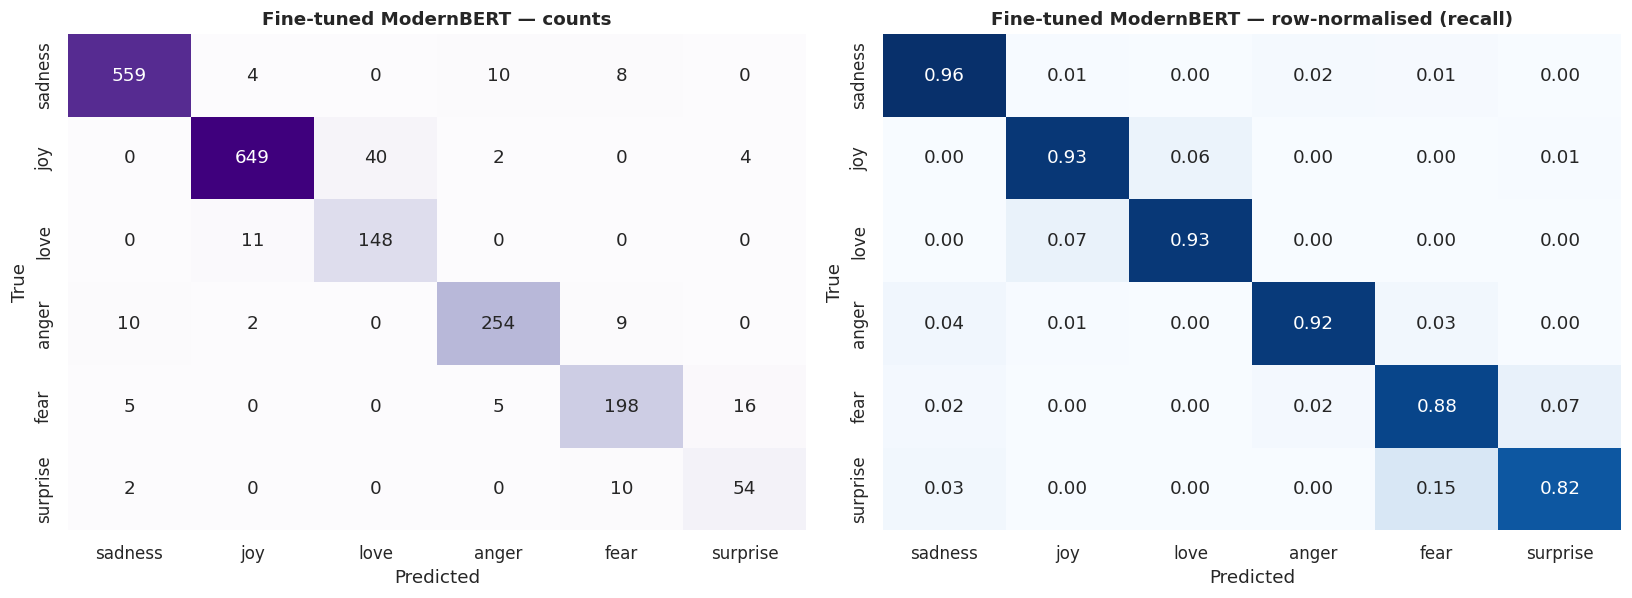

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.6))
sns.heatmap(confusion_matrix(y_true, bert_pred), annot=True, fmt="d", cmap="Purples", cbar=False, ax=axes[0],
            xticklabels=LABELS, yticklabels=LABELS)
axes[0].set_title("Fine-tuned ModernBERT — counts")
sns.heatmap(confusion_matrix(y_true, bert_pred, normalize="true"), annot=True, fmt=".2f", cmap="Blues", cbar=False,
            ax=axes[1], xticklabels=LABELS, yticklabels=LABELS)
axes[1].set_title("Fine-tuned ModernBERT — row-normalised (recall)")
for ax in axes: ax.set_xlabel("Predicted"); ax.set_ylabel("True")
plt.tight_layout(); plt.show()

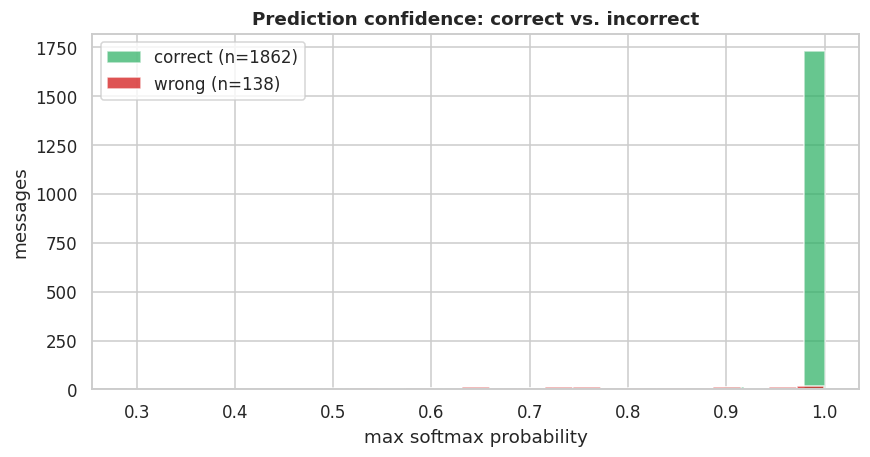

Mean confidence -> correct: 0.982 | wrong: 0.777


In [16]:
# Is the model's confidence trustworthy? Compare confidence when right vs. wrong.
conf = probs.max(1); correct = bert_pred == y_true
plt.figure(figsize=(9, 4.2))
plt.hist(conf[correct],  bins=25, alpha=.7, color="#27ae60", label=f"correct (n={correct.sum()})")
plt.hist(conf[~correct], bins=25, alpha=.8, color="#d62828", label=f"wrong (n={(~correct).sum()})")
plt.title("Prediction confidence: correct vs. incorrect"); plt.xlabel("max softmax probability"); plt.ylabel("messages")
plt.legend(); plt.show()
print(f"Mean confidence -> correct: {conf[correct].mean():.3f} | wrong: {conf[~correct].mean():.3f}")

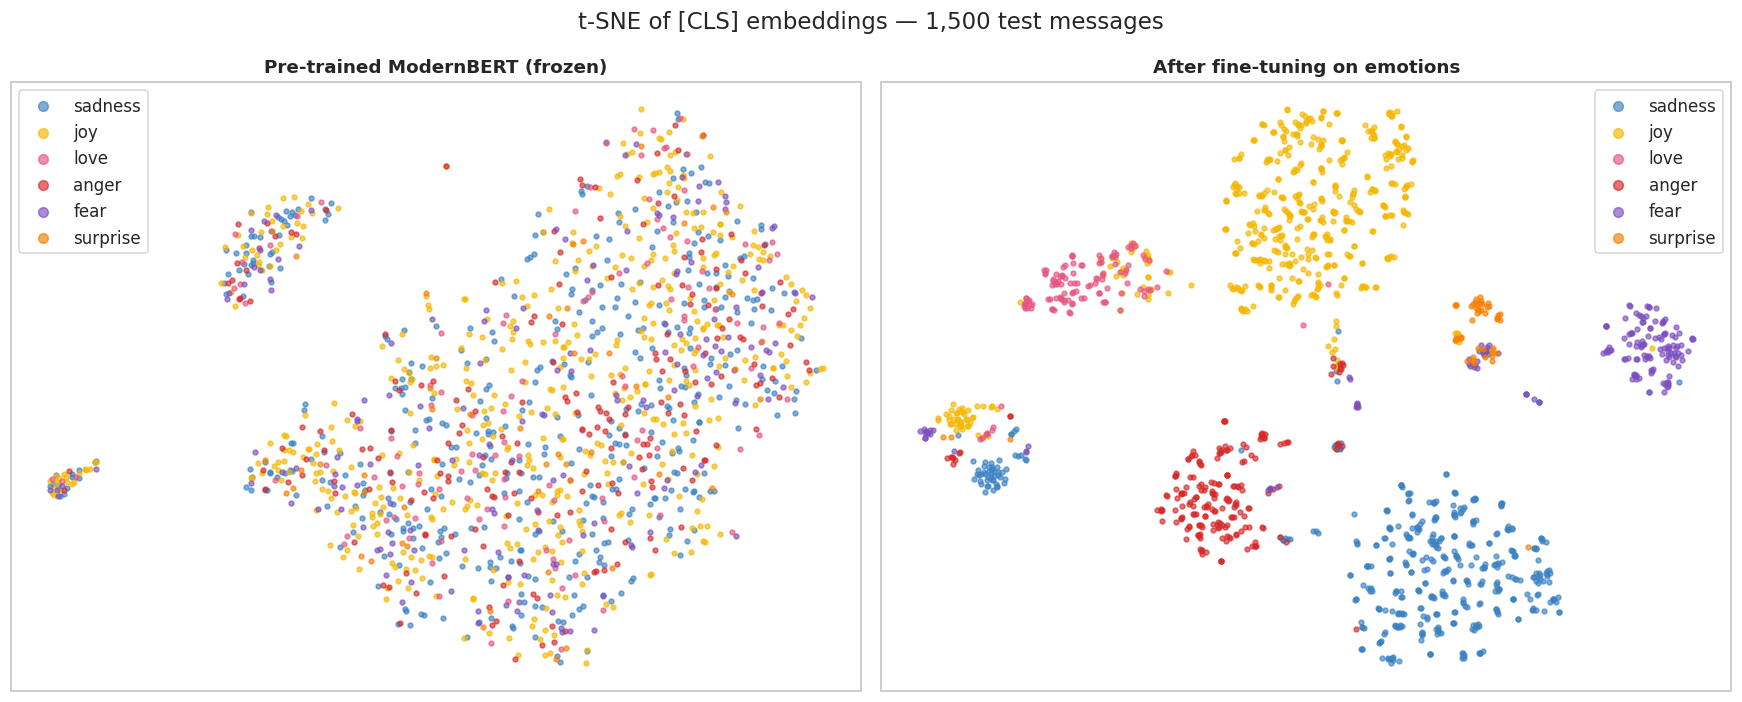

In [17]:
emb_test_after = cls_embeddings(trainer.model, test_df.text.tolist())
tsne_after = TSNE(n_components=2, perplexity=35, init="pca", random_state=SEED).fit_transform(emb_test_after[viz_idx])

viz_labels = y_true[viz_idx]
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for ax, emb, title in zip(axes, [tsne_before, tsne_after],
                          ["Pre-trained ModernBERT (frozen)", "After fine-tuning on emotions"]):
    for k, name in enumerate(LABELS):
        m = viz_labels == k
        ax.scatter(emb[m, 0], emb[m, 1], s=10, alpha=.65, c=COLORS[name], label=name)
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([]); ax.legend(markerscale=2)
plt.suptitle("t-SNE of [CLS] embeddings — 1,500 test messages", fontsize=15); plt.tight_layout(); plt.show()

In [18]:
err = test_df.assign(pred=bert_pred, conf=probs.max(1))
err = err[err.label != err.pred].sort_values("conf", ascending=False).head(10)
err = err.assign(true=err.label.map(id2label), predicted=err.pred.map(id2label), confidence=err.conf.round(3))
pd.set_option("display.max_colwidth", 110)
display(err[["text", "true", "predicted", "confidence"]].reset_index(drop=True))

cm = confusion_matrix(y_true, bert_pred); np.fill_diagonal(cm, 0)
pairs = sorted(((cm[i, j], LABELS[i], LABELS[j]) for i in range(NUM_LABELS) for j in range(NUM_LABELS)), reverse=True)[:4]
print("Most frequent confusions (true -> predicted):")
for n, a, b in pairs:
    print(f"  {a:>8} -> {b:<8} : {n} messages")

,text,true,predicted,confidence
0,i feel inside cause life is like a game sometimes but then you came around me the walls just disappeared n...,fear,sadness,1.000
1,i really dont like quinn because i feel like she will just end up hurting barney and i hated the lame ted ...,anger,sadness,1.000
2,i found myself feeling inhibited and shushing her quite a lot,sadness,fear,0.999
3,i do feel terribly remourseful that i didnt stay faithful to my plans and get him sooner,love,joy,0.998
4,i was lying in bed last night after a day of making experiments from the usual suspects fabric plastic and...,anger,fear,0.998
5,im not sure if its just me who feels this way or if its everyone but tortured souls dont make for the best...,anger,fear,0.998
6,i have reported feeling marginalized intimidated and or subjected to threats of retaliation,fear,sadness,0.993
7,i feel unprotected a class post count link href http reprogramming in process,sadness,fear,0.990
8,i don t really know the oldest one very well and his mothering mother seems to feel that he is not sweet,joy,love,0.990
9,i guess feelings aren t meant to be inhibited or prohibited,fear,sadness,0.990


Most frequent confusions (true -> predicted):
       joy -> love     : 40 messages
      fear -> surprise : 16 messages
      love -> joy      : 11 messages
  surprise -> fear     : 10 messages


In [19]:
def hex2rgb(h): h = h.lstrip("#"); return ",".join(str(int(h[i:i+2], 16)) for i in (0, 2, 4))

def explain(text):
    m = trainer.model.eval()
    enc = tokenizer(text, return_tensors="pt", truncation=True, max_length=MAX_LEN).to(device)
    store = {}
    def hook(mod, inp, out):
        out.retain_grad(); store["emb"] = out
    handle = m.get_input_embeddings().register_forward_hook(hook)
    try:
        m.zero_grad()
        logits = m(**enc).logits
        p = torch.softmax(logits, -1)[0].detach().cpu().numpy()
        k = int(p.argmax())
        logits[0, k].backward()
        emb = store["emb"]
        sal = (emb.grad * emb).sum(-1)[0].abs().detach().cpu().numpy()
    finally:
        handle.remove()

    toks = tokenizer.convert_ids_to_tokens(enc["input_ids"][0].tolist())
    keep = [i for i, t in enumerate(toks) if t not in tokenizer.all_special_tokens]
    w = sal[keep] / (sal[keep].max() + 1e-9)
    rgb = hex2rgb(COLORS[LABELS[k]])
    spans = "".join(f'<span style="background:rgba({rgb},{a:.2f});padding:2px 4px;margin:1px;border-radius:4px">'
                    f'{toks[i].replace(chr(288), "")}</span>' for i, a in zip(keep, w))
    display(HTML(f'<div style="font-family:monospace;font-size:15px;margin:8px 0">{spans} '
                 f'&nbsp;→ <b style="color:rgb({rgb})">{LABELS[k].upper()}</b> ({p[k]:.1%})</div>'))

for s in ["i am absolutely furious that they cancelled my flight without telling me",
          "i feel so grateful and warm whenever my family is around",
          "i was terrified when i heard footsteps behind me in the dark",
          "wow i honestly did not expect to win that award"]:
    explain(s)

In [20]:
b, p, f = res_df.loc["TF-IDF + LogReg"], res_df.loc["Frozen ModernBERT + LogReg (probe)"], res_df.loc["Fine-tuned ModernBERT"]
print("SUMMARY OF THIS RUN")
print("=" * 64)
print(f"TF-IDF + LogReg              : Acc {b.Accuracy:.4f} | Macro-F1 {b['Macro-F1']:.4f}")
print(f"Frozen ModernBERT + probe    : Acc {p.Accuracy:.4f} | Macro-F1 {p['Macro-F1']:.4f}")
print(f"Fine-tuned ModernBERT        : Acc {f.Accuracy:.4f} | Macro-F1 {f['Macro-F1']:.4f}")
print("-" * 64)
print(f"Fine-tuning vs. TF-IDF baseline   : {100*(f['Macro-F1']-b['Macro-F1']):+.2f} macro-F1 points")
print(f"Fine-tuning vs. frozen features   : {100*(f['Macro-F1']-p['Macro-F1']):+.2f} macro-F1 points")
best_c, worst_c = f1_table["Fine-tuned ModernBERT"].idxmax(), f1_table["Fine-tuned ModernBERT"].idxmin()
print(f"Easiest class  : {best_c} (F1 {f1_table.loc[best_c, 'Fine-tuned ModernBERT']:.3f})")
print(f"Hardest class  : {worst_c} (F1 {f1_table.loc[worst_c, 'Fine-tuned ModernBERT']:.3f})")
print(f"Train time     : {train_result.metrics['train_runtime']:.0f}s for {EPOCHS} epochs on {device}")

SUMMARY OF THIS RUN
TF-IDF + LogReg              : Acc 0.8690 | Macro-F1 0.8345
Frozen ModernBERT + probe    : Acc 0.4300 | Macro-F1 0.3609
Fine-tuned ModernBERT        : Acc 0.9310 | Macro-F1 0.8928
----------------------------------------------------------------
Fine-tuning vs. TF-IDF baseline   : +5.83 macro-F1 points
Fine-tuning vs. frozen features   : +53.19 macro-F1 points
Easiest class  : sadness (F1 0.966)
Hardest class  : surprise (F1 0.771)
Train time     : 315s for 3 epochs on cuda
